# ML Assignment 2
## M.Tech - AIMLZG565

### NAME: Ameya S Pedgaonkar
### BITS ID: 2026AJ05079

**Problem:** Predict whether an online shopping session ends in a purchase (`Revenue`).

**Dataset:** UCI Online Shoppers Purchasing Intention Dataset (12,330 sessions).

**Required classifiers:** Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, and Support Vector Machine.

**Required metrics:** Accuracy, ROC-AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC).

**Advanced analysis included:** class-imbalance diagnostics, leakage-aware feature selection, exploratory visualizations, ROC curves, confusion matrices, feature-importance inspection, and export of a Streamlit-ready project.


## 1. Setup and imports

In [1]:
%pip install --upgrade --force-reinstall numpy==1.26.4 scipy==1.13.1 scikit-learn==1.5.2 pandas==2.2.3

  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached scipy-1.13.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (60 kB)
  Using cached scikit_learn-1.5.2-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (13 kB)
  Using cached pandas-2.2.3-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (89 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached python_dateutil-4.0.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
Using cached scipy-1.13.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_

In [1]:
import os
import sys
import json
import time
import zipfile
import urllib.request
import urllib.error
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
)
from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.12.7
pandas: 2.2.3
NumPy: 1.26.4


## 2. Download and load the real UCI dataset
The notebook first tries UCI's direct CSV endpoint, then the UCI `ucimlrepo` interface.

In [4]:
DATA_FILE = Path("online_shoppers_intention.csv")
DATA_URLS = [
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv",
]

if not DATA_FILE.exists():
    download_error = None
    for url in DATA_URLS:
        try:
            print("Trying official UCI CSV:", url)
            urllib.request.urlretrieve(url, DATA_FILE)
            print("Downloaded:", DATA_FILE.resolve())
            break
        except Exception as exc:
            download_error = exc
            print("Direct download failed:", repr(exc))
            if DATA_FILE.exists():
                DATA_FILE.unlink()

if not DATA_FILE.exists():
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        print("Installing ucimlrepo fallback...")
        %pip -q install ucimlrepo
        from ucimlrepo import fetch_ucirepo
    try:
        uci_data = fetch_ucirepo(id=468)
        X_uci = uci_data.data.features.copy()
        y_uci = uci_data.data.targets.copy()
        raw_df = pd.concat([X_uci, y_uci], axis=1)
        raw_df.to_csv(DATA_FILE, index=False)
        print("Fetched dataset via ucimlrepo and saved:", DATA_FILE.resolve())
    except Exception as exc:
        raise RuntimeError(
            "Could not download the dataset. Download online_shoppers_intention.csv from "
            "https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset "
            "and upload it into this notebook's working directory as online_shoppers_intention.csv."
        ) from exc

if 'raw_df' not in globals():
    raw_df = pd.read_csv(DATA_FILE)

print("Dataset shape:", raw_df.shape)
display(raw_df.head())

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Dataset validation and description
The original file contains 17 input attributes and the binary `Revenue` target. This notebook excludes `PageValues` from model inputs because it is a conversion-related analytics measure that can provide outcome-proximate information, making it a leakage risk for an intention-prediction task.

In [7]:
TARGET = "Revenue"
EXPECTED_COLUMNS = {
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay", "Month",
    "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType",
    "Weekend", "Revenue",
}
missing_expected = sorted(EXPECTED_COLUMNS.difference(raw_df.columns))
if missing_expected:
    raise ValueError(f"Dataset is missing expected columns: {missing_expected}")

print("Rows:", len(raw_df))
print("Original columns (including target):", raw_df.shape[1])
print("Duplicate rows:", int(raw_df.duplicated().sum()))
print("Missing values by column:")
display(raw_df.isna().sum().to_frame("missing_count").T)
print("Data types:")
display(raw_df.dtypes.to_frame("dtype").T)

Rows: 12330
Original columns (including target): 18
Duplicate rows: 125
Missing values by column:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
missing_count,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Data types:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
dtype,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,object,int64,int64,int64,int64,object,bool,bool


## 4. Exploratory data analysis (EDA)
The target is imbalanced: the UCI description reports 10,422 non-purchase sessions (84.5%) and 1,908 purchase sessions (15.5%). Accuracy alone can therefore be misleading. So, six required metrics will be reported, along with purchase-class recall and F1.

Target counts (0 = No Purchase, 1 = Purchase):


,sessions
Revenue,
No Purchase,10422
Purchase,1908


Purchase rate: 15.47%
Majority-class accuracy baseline: 84.53% (would have 0 purchase recall)


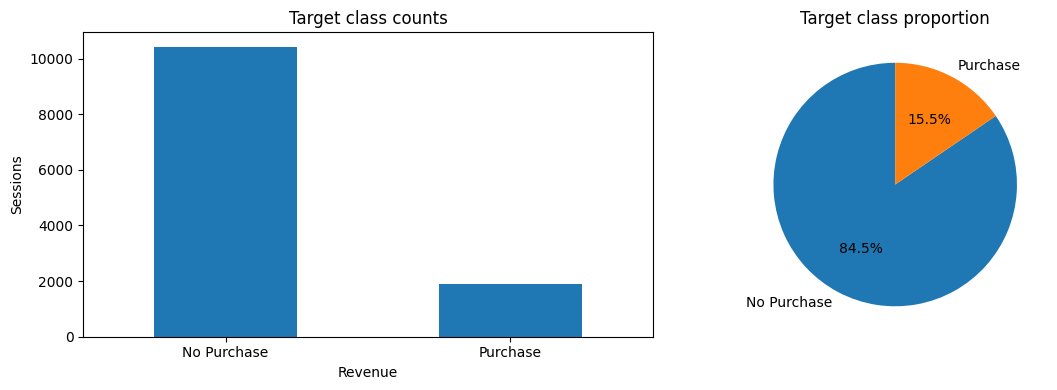

In [10]:
# Normalizing Revenue into 0 = no purchase, 1 = purchase.
def encode_revenue(series):
    if pd.api.types.is_bool_dtype(series):
        return series.astype(int)
    if pd.api.types.is_numeric_dtype(series):
        values = pd.to_numeric(series, errors="coerce")
        if values.isna().any() or not set(values.unique()).issubset({0, 1}):
            raise ValueError("Revenue numeric values must be 0/1.")
        return values.astype(int)
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0, "yes": 1, "no": 0}
    encoded = series.astype(str).str.strip().str.lower().map(mapping)
    if encoded.isna().any():
        raise ValueError("Unexpected Revenue labels. Expected True/False or 1/0.")
    return encoded.astype(int)

raw_df[TARGET] = encode_revenue(raw_df[TARGET])
print("Target counts (0 = No Purchase, 1 = Purchase):")
display(raw_df[TARGET].value_counts().rename(index={0:"No Purchase", 1:"Purchase"}).to_frame("sessions"))
class_share = raw_df[TARGET].value_counts(normalize=True).sort_index() * 100
print(f"Purchase rate: {class_share.loc[1]:.2f}%")
print(f"Majority-class accuracy baseline: {class_share.max():.2f}% (would have 0 purchase recall)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw_df[TARGET].value_counts().sort_index().rename(index={0:"No Purchase",1:"Purchase"}).plot(
    kind="bar", ax=axes[0], title="Target class counts", rot=0
)
axes[0].set_ylabel("Sessions")
axes[1].pie(
    raw_df[TARGET].value_counts().sort_index(),
    labels=["No Purchase", "Purchase"], autopct="%.1f%%", startangle=90
)
axes[1].set_title("Target class proportion")
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


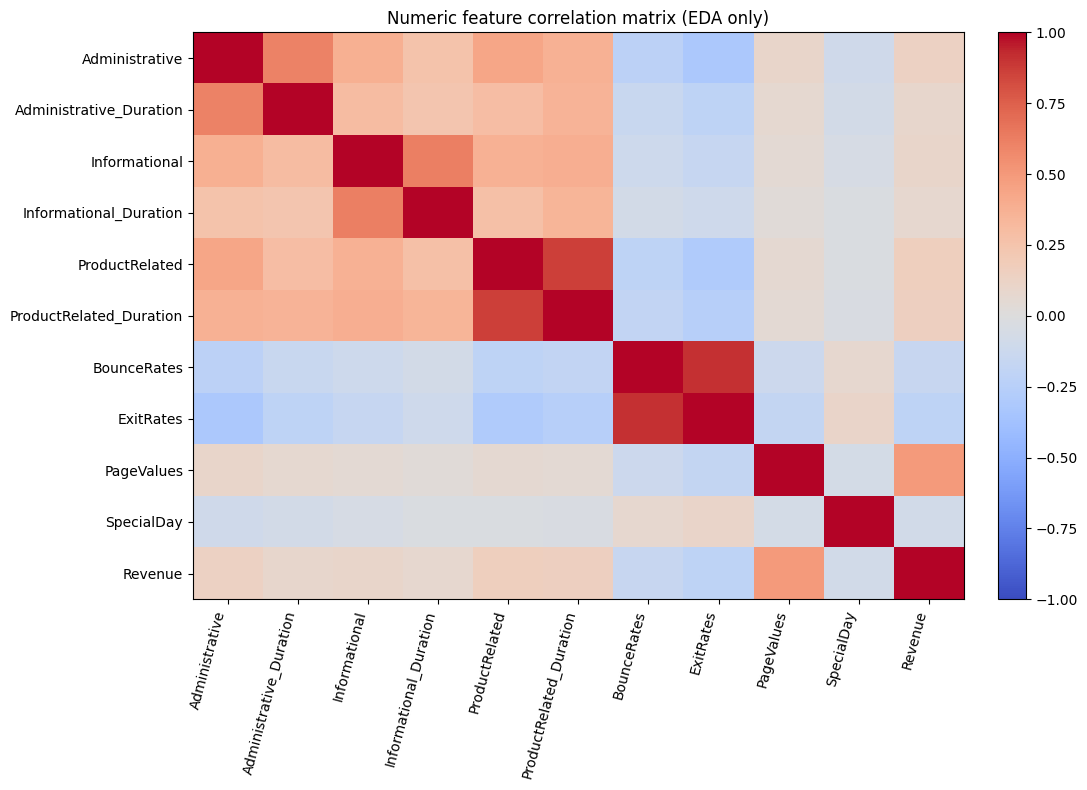

In [12]:
# Numeric variables are inspected before modelling. PageValues is intentionally excluded from the model feature set below.
eda_numeric = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
display(raw_df[eda_numeric].describe().T.round(3))

corr = raw_df[eda_numeric + [TARGET]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Numeric feature correlation matrix (EDA only)")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

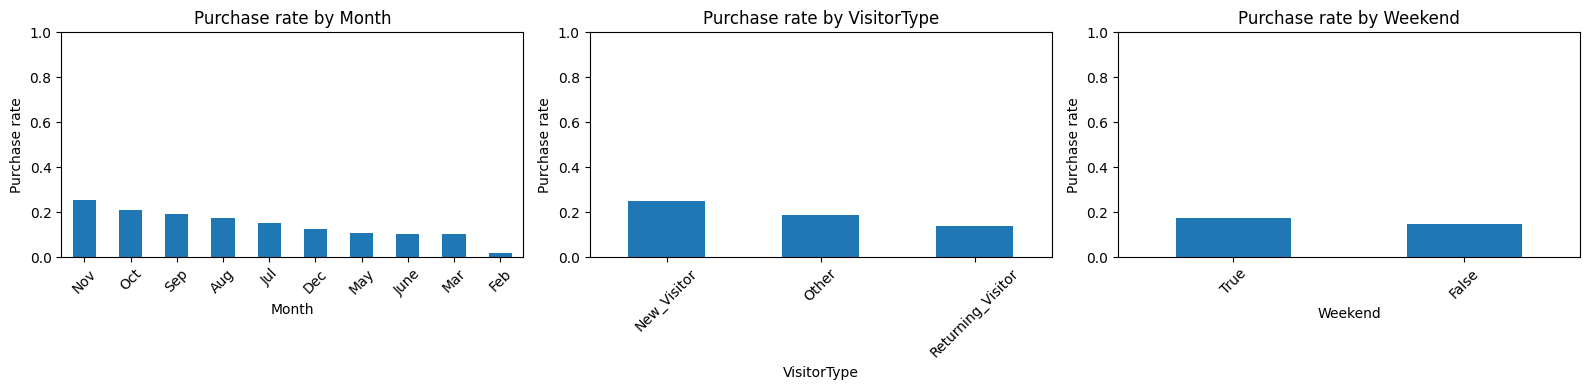

In [14]:
# Purchase rate by selected categorical variables.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Month", "VisitorType", "Weekend"]):
    purchase_rate = raw_df.groupby(col, dropna=False)[TARGET].mean().sort_values(ascending=False)
    purchase_rate.plot(kind="bar", ax=ax, title=f"Purchase rate by {col}", rot=45)
    ax.set_ylabel("Purchase rate")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 5. Leakage-aware feature selection and preprocessing
- `Revenue` is the target and is never included in `X`.
- `PageValues` is excluded from model inputs due to its conversion-related definition and potential target leakage.
- `Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, and `Weekend` are treated as categorical variables (even where stored as integers).
- Numeric variables are median-imputed and standardized. Categorical variables are mode-imputed and one-hot encoded.
- Preprocessing is inside each model pipeline, so transformations are fitted only on the training split.

In [17]:
NUMERIC_FEATURES = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay",
]
CATEGORICAL_FEATURES = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = raw_df[FEATURE_COLUMNS].copy()
y = raw_df[TARGET].copy()

ohe_parameters = inspect.signature(OneHotEncoder).parameters
ohe_kwargs = {"handle_unknown": "ignore"}
if "sparse_output" in ohe_parameters:
    ohe_kwargs["sparse_output"] = False
else:
    ohe_kwargs["sparse"] = False

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(**ohe_kwargs)),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
], remainder="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training purchase rate:", round(y_train.mean() * 100, 2), "%")
print("Test purchase rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 9864 | Test rows: 2466
Training purchase rate: 15.47 %
Test purchase rate: 15.49 %


## 6. Training the five required classifiers
All classifiers use the same stratified train/test split and the same preprocessing design. Class weighting is used for Logistic Regression, Decision Tree, and SVM to account for the minority purchase class. Gaussian Naive Bayes receives dense one-hot encoded features.

In [20]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2500, class_weight="balanced", solver="lbfgs", random_state=RANDOM_STATE, C=0.5
    ),
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini", min_samples_leaf=5, max_depth=7, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=15, weights="distance", metric="minkowski", p=2, n_jobs=-1
    ),
    "Gaussian Naive Bayes": GaussianNB(var_smoothing=1e-9),
    "Support Vector Machine": SVC(
        kernel="rbf", C=1.0, class_weight="balanced", probability=False,
        random_state=RANDOM_STATE
    ),
}

fitted_models = {}
training_seconds = {}
for model_name, classifier in models.items():
    print(f"Training {model_name} ...")
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier)),
    ])
    start = time.time()
    pipeline.fit(X_train, y_train)
    training_seconds[model_name] = time.time() - start
    fitted_models[model_name] = pipeline
    print(f"  completed in {training_seconds[model_name]:.2f} seconds")

Training Logistic Regression ...
  completed in 0.87 seconds
Training Decision Tree ...
  completed in 0.25 seconds
Training K-Nearest Neighbors ...
  completed in 0.07 seconds
Training Gaussian Naive Bayes ...
  completed in 0.11 seconds
Training Support Vector Machine ...
  completed in 12.36 seconds


## 7. Evaluate all models using the six required metrics
ROC-AUC is computed using predicted probabilities where available and continuous decision scores for the SVM. Precision, Recall and F1 are calculated for the positive class (`Revenue=1`). MCC provides a balanced correlation-style summary across all confusion-matrix outcomes.

In [23]:
def positive_class_score(estimator, features):
    """Continuous score oriented toward Revenue=1 for ROC-AUC."""
    if hasattr(estimator, "predict_proba"):
        probabilities = estimator.predict_proba(features)
        classes = list(estimator.classes_)
        return probabilities[:, classes.index(1)]
    if hasattr(estimator, "decision_function"):
        scores = estimator.decision_function(features)
        classes = list(estimator.classes_)
        return scores if classes.index(1) == 1 else -scores
    return estimator.predict(features).astype(float)

results = []
predictions = {}
scores_by_model = {}
for model_name, pipeline in fitted_models.items():
    y_pred = pipeline.predict(X_test).astype(int)
    y_score = positive_class_score(pipeline, X_test)
    predictions[model_name] = y_pred
    scores_by_model[model_name] = y_score
    results.append({
        "ML Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Training Time (sec)": training_seconds[model_name],
    })

metrics_df = pd.DataFrame(results).sort_values(
    ["F1", "ROC-AUC"], ascending=False
).reset_index(drop=True)
display(metrics_df.style.format({
    "Accuracy":"{:.4f}", "ROC-AUC":"{:.4f}", "Precision":"{:.4f}",
    "Recall":"{:.4f}", "F1":"{:.4f}", "MCC":"{:.4f}",
    "Training Time (sec)":"{:.2f}",
}))

,ML Model,Accuracy,ROC-AUC,Precision,Recall,F1,MCC,Training Time (sec)
0,Logistic Regression,0.6310,0.7352,0.2600,0.7487,0.3860,0.2607,0.87
1,Support Vector Machine,0.6476,0.7360,0.2596,0.6885,0.3771,0.2417,12.36
2,Decision Tree,0.6715,0.6999,0.2643,0.6283,0.3721,0.2309,0.25
3,Gaussian Naive Bayes,0.2709,0.6774,0.1719,0.9712,0.2921,0.1245,0.11
4,K-Nearest Neighbors,0.8382,0.7037,0.3836,0.0733,0.1231,0.1104,0.07


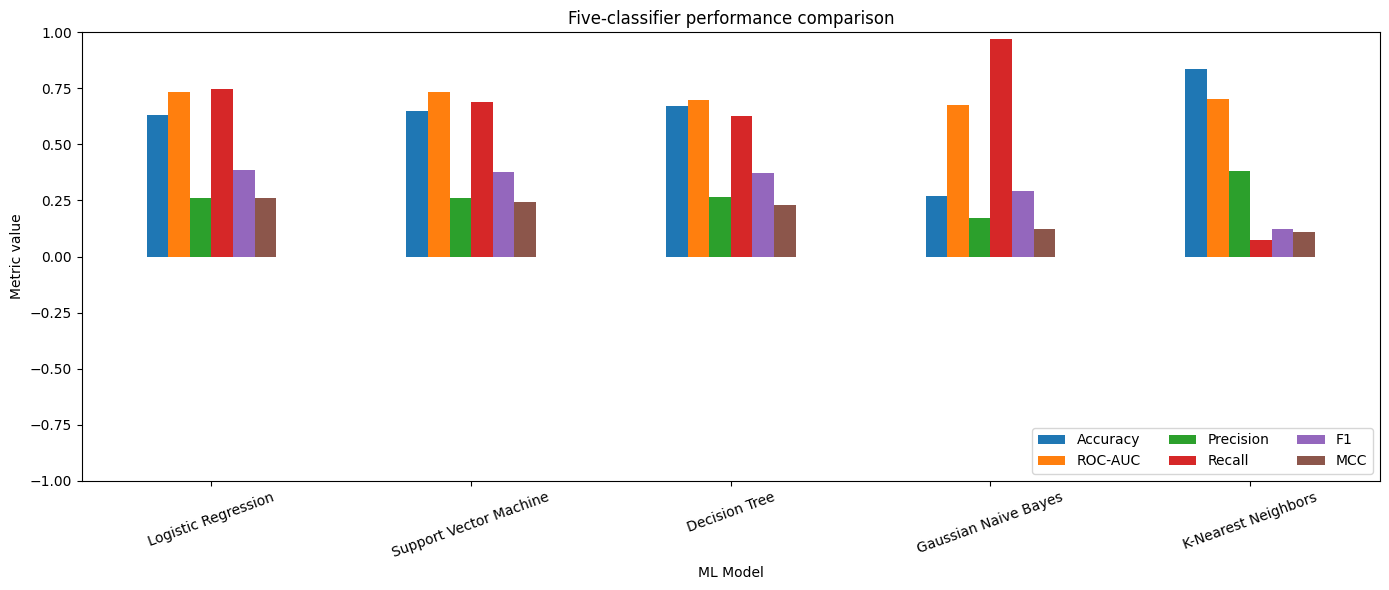

In [25]:
# Visual comparison of all required metrics (training time omitted from this chart).
metric_columns = ["Accuracy", "ROC-AUC", "Precision", "Recall", "F1", "MCC"]
plot_df = metrics_df.set_index("ML Model")[metric_columns]
ax = plot_df.plot(kind="bar", figsize=(14, 6), ylim=(-1, 1), rot=20)
ax.set_title("Five-classifier performance comparison")
ax.set_ylabel("Metric value")
ax.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

## 8. ROC curves and confusion matrices
ROC curves compare the trade-off between true-positive rate and false-positive rate across thresholds. Confusion matrices show the errors made at each model's default decision threshold.

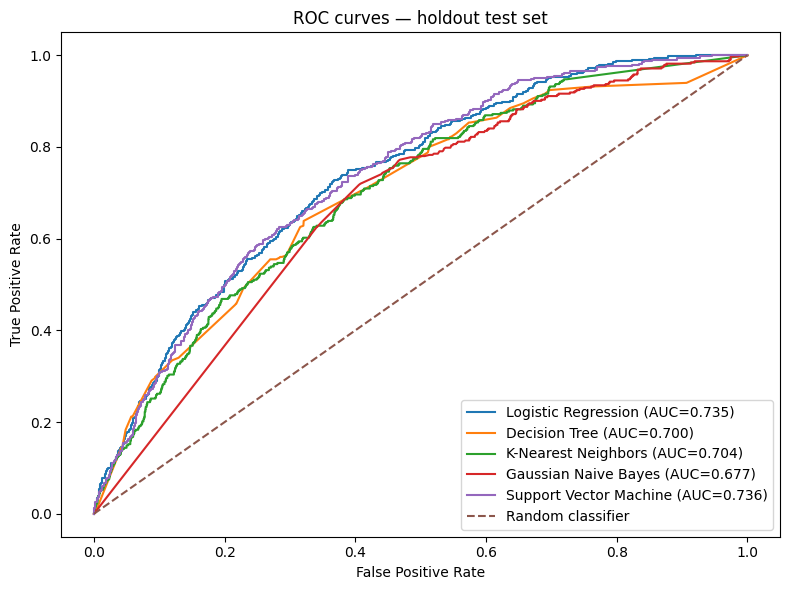

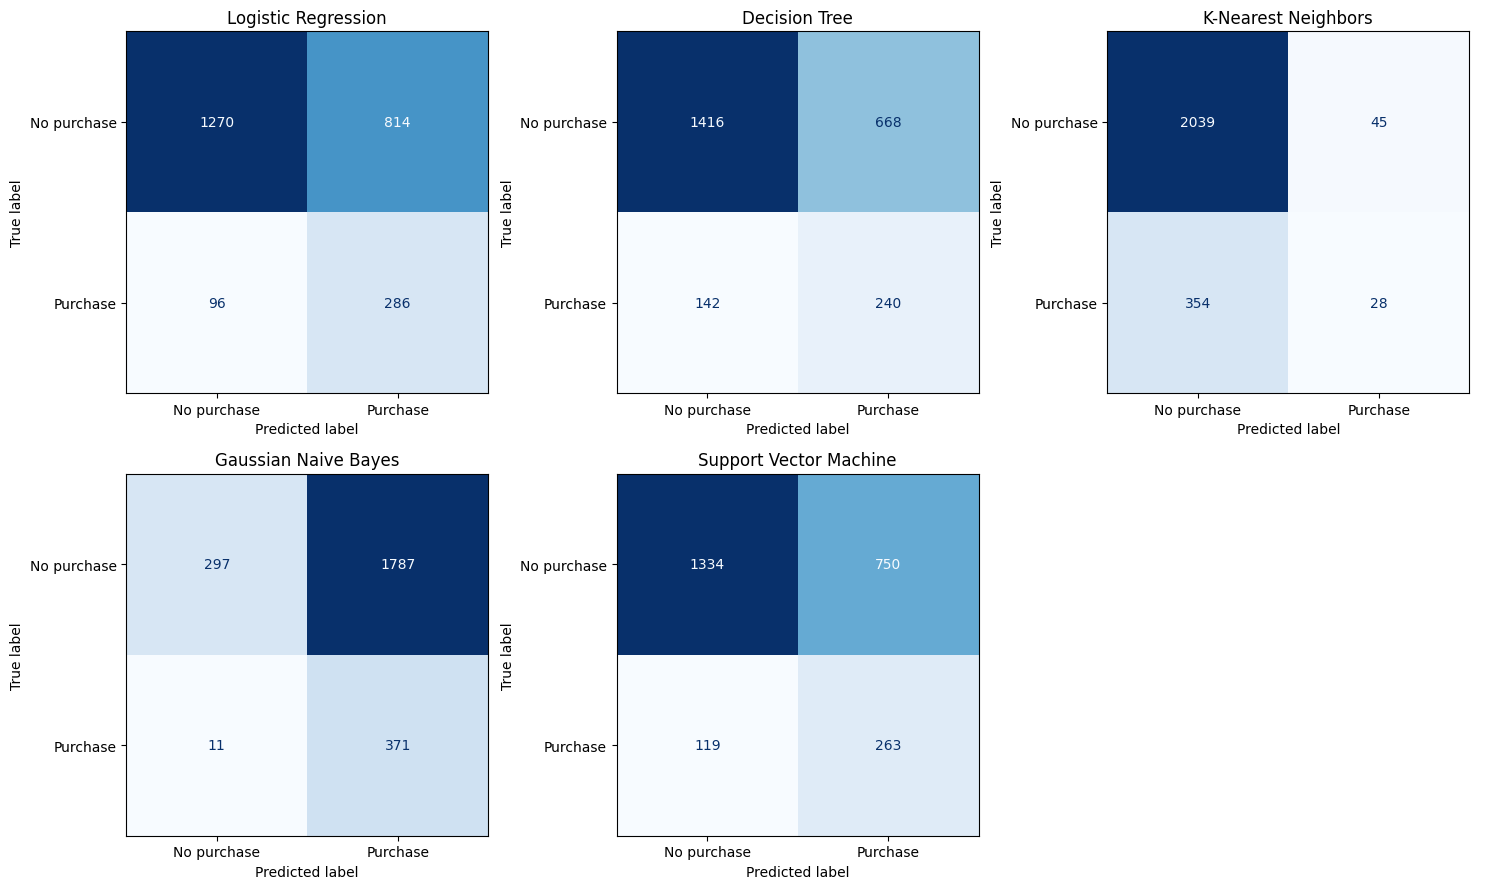

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))
for model_name in fitted_models:
    fpr, tpr, _ = roc_curve(y_test, scores_by_model[model_name])
    curve_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{model_name} (AUC={curve_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves — holdout test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (model_name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, y_pred, labels=[0, 1]),
        display_labels=["No purchase", "Purchase"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(model_name)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

## 9. Detailed classification reports and feature insights

\n==============================================================================
Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.93      0.61      0.74      2084
    Purchase       0.26      0.75      0.39       382

    accuracy                           0.63      2466
   macro avg       0.59      0.68      0.56      2466
weighted avg       0.83      0.63      0.68      2466

\n==============================================================================
Decision Tree
              precision    recall  f1-score   support

 No Purchase       0.91      0.68      0.78      2084
    Purchase       0.26      0.63      0.37       382

    accuracy                           0.67      2466
   macro avg       0.59      0.65      0.57      2466
weighted avg       0.81      0.67      0.71      2466

\n==============================================================================
K-Nearest Neighbors
              precision    recall  f1-score   sup

,Feature,Importance
7,numeric__ExitRates,0.496084
5,numeric__ProductRelated_Duration,0.119006
6,numeric__BounceRates,0.069337
16,categorical__Month_Nov,0.053640
0,numeric__Administrative,0.043961
4,numeric__ProductRelated,0.032870
8,numeric__SpecialDay,0.026754
1,numeric__Administrative_Duration,0.024694
14,categorical__Month_Mar,0.016916
71,categorical__VisitorType_Returning_Visitor,0.012446


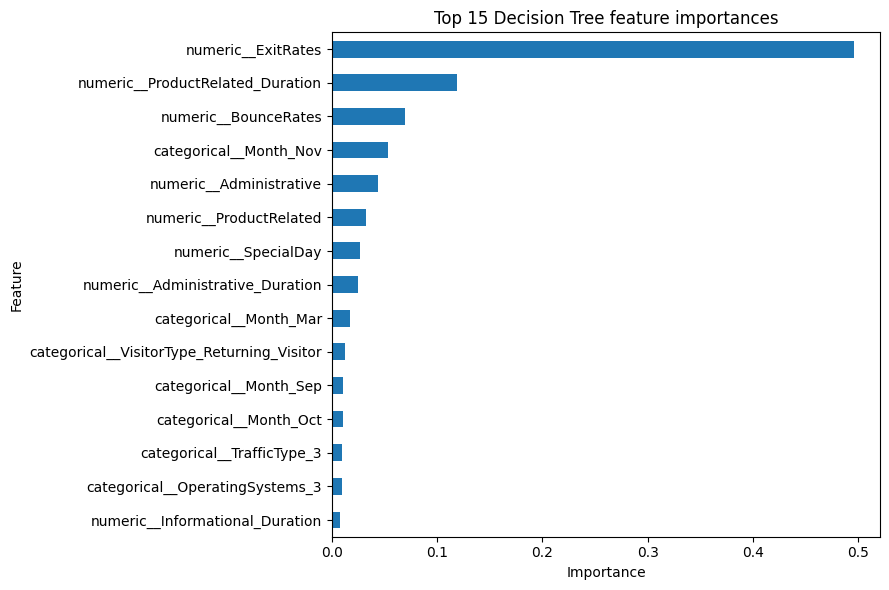

In [32]:
for model_name, y_pred in predictions.items():
    print("\\n" + "=" * 78)
    print(model_name)
    print(classification_report(
        y_test, y_pred, labels=[0, 1],
        target_names=["No Purchase", "Purchase"], zero_division=0
    ))

# Decision-tree feature importance from the fitted preprocessing + tree pipeline.
tree_pipeline = fitted_models["Decision Tree"]
try:
    transformed_names = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()
    importances = tree_pipeline.named_steps["classifier"].feature_importances_
    importance_df = pd.DataFrame({
        "Feature": transformed_names,
        "Importance": importances,
    }).sort_values("Importance", ascending=False).head(15)
    display(importance_df)
    ax = importance_df.sort_values("Importance").plot(
        x="Feature", y="Importance", kind="barh", figsize=(9, 6), legend=False
    )
    ax.set_title("Top 15 Decision Tree feature importances")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Feature-name extraction was not available in this scikit-learn version:", exc)

## 10. Select the overall winner and generate observations
The winner is selected using positive-class F1 as the primary ranking metric and ROC-AUC as the secondary indicator. This avoids choosing a model that ranks sessions well but fails to identify any purchase sessions at the default decision threshold. The conclusion is based on this dataset split and should not be generalized without further validation.

Here, for this dataset and evaluation results, Logistic Regression wins.

Logistic Regression was selected as the it achieved the highest F1-score of 0.3860 among all five models, indicating a better balance between precision and recall when identifying customers who are likely to make a purchase.

It also achieved an ROC-AUC score of 0.7352, which is very close to the highest score of 0.7360 obtained by SVM. Although KNN recorded the highest accuracy of 0.8382, its recall was only 0.0733, meaning it failed to identify most actual purchasing sessions. Similarly, Gaussian Naive Bayes achieved high recall but had very low precision.

Since the dataset is imbalanced, accuracy alone is not a reliable measure of model performance. Therefore, greater importance was given to F1-score, supported by ROC-AUC, to select a model that could identify purchasing sessions more effectively.

Considering these factors, Logistic Regression provides the most balanced overall performance and was selected as the final model for this classification problem.

Final Observations:

## Observations on Model Performance

1. **Logistic Regression:** Achieved the highest F1-score of 0.3860 and MCC of 0.2607, indicating the best balance between precision and recall among all five models.

2. **Decision Tree:** Achieved an accuracy of 67.15% and an F1-score of 0.3721. It showed moderate performance across the evaluation metrics.

3. **K-Nearest Neighbors (KNN):** Achieved the highest accuracy of 83.82%, but its recall was only 0.0733. This indicates that it failed to identify most actual purchasing sessions.

4. **Gaussian Naive Bayes:** Achieved the highest recall of 0.9712, but its precision was only 0.1719, resulting in a large number of false-positive predictions.

5. **Support Vector Machine (SVM):** Achieved the highest ROC-AUC of 0.7360, showing good classification ability. However, its F1-score of 0.3771 was slightly lower than Logistic Regression.

### Overall Winner: Logistic Regression

In [35]:
winner_row = metrics_df.iloc[0]
WINNER = winner_row["ML Model"]
print("Overall winner (positive-class F1 first, ROC-AUC tie-break):", WINNER)
print("Winner metrics:")
display(winner_row.to_frame("value"))

for _, row in metrics_df.iterrows():
    print(
        f"{row['ML Model']}: accuracy={row['Accuracy']:.3f}, "
        f"ROC-AUC={row['ROC-AUC']:.3f}, precision={row['Precision']:.3f}, "
        f"recall={row['Recall']:.3f}, F1={row['F1']:.3f}, MCC={row['MCC']:.3f}."
    )

Overall winner (positive-class F1 first, ROC-AUC tie-break): Logistic Regression
Winner metrics:


,value
ML Model,Logistic Regression
Accuracy,0.630981
ROC-AUC,0.735201
Precision,0.26
Recall,0.748691
F1,0.385965
MCC,0.26065
Training Time (sec),0.871546


Logistic Regression: accuracy=0.631, ROC-AUC=0.735, precision=0.260, recall=0.749, F1=0.386, MCC=0.261.
Support Vector Machine: accuracy=0.648, ROC-AUC=0.736, precision=0.260, recall=0.688, F1=0.377, MCC=0.242.
Decision Tree: accuracy=0.672, ROC-AUC=0.700, precision=0.264, recall=0.628, F1=0.372, MCC=0.231.
Gaussian Naive Bayes: accuracy=0.271, ROC-AUC=0.677, precision=0.172, recall=0.971, F1=0.292, MCC=0.124.
K-Nearest Neighbors: accuracy=0.838, ROC-AUC=0.704, precision=0.384, recall=0.073, F1=0.123, MCC=0.110.
